<a href="https://colab.research.google.com/github/MahuL88/Latihan/blob/main/Proyek_TorchUp_Filkom.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Library

In [ ]:
import pandas as pd  # Pandas untuk manipulasi dan analisis data
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from matplotlib.pyplot import imshow

from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import datasets, transforms, models,utils
import torchvision.transforms as transforms

tensor adalah wadah data angka yang fleksibel(dimensi brpapun). Dataset : bungkus raw data dan membuat struktur, Dataloader :  yg membagi menjadi beberapa batch. torchvision ; library utk CV/ML. transforms.Compose menggabungkan pemrosesan gambar menjadi satu kesatuan perintah

# Load Dataset

In [ ]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5,), (0.5,))
     ])

In [ ]:
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [ ]:
for images, labels in train_loader:
    print('Image batch dimensions:', images.shape)
    print('Image label dimensions:', labels.shape)
    break

Image batch dimensions: torch.Size([64, 1, 28, 28])
Image label dimensions: torch.Size([64])


# Modeling

In [ ]:
from torch.nn.modules import Conv2d
from torch.nn.modules.pooling import MaxPool2d


class simpleCNN(nn.Module):
    def __init__(self):
        super(simpleCNN, self).__init__() # mengaktifkan nn.Module

        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1), # input jlh warna, output jlh pola, ukuran 3x3 dengan tambahan padding
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2), #28x28 -> 14x14          # stride itu langkah pergeseran kotak

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2), #14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=32*7*7, out_features=128),
            nn.ReLU(),
            nn.Linear(in_features=128, out_features=10)
        )

    def forward(self, x):
        x=self.features(x)
        x=self.classifier(x)
        return x

Setiap layer menghasilkan ouput dengan ukuran tensor sebagai berikut:

| Layer |   Output   |
| --- | --- |
|input  | 1 x 28 x 28|
|Conv1  |16 x 28 x 28|
|MaxPool|16 x 14 x 14|
|Conv2  |32 x 14 x 14|
|MaxPool|32 x  7 x  7|
|Flatten|1568        |

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Menggunakan Device: {device}")

model = simpleCNN()
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


Menggunakan Device: cpu


In [ ]:
epochs = 5

for epoch in range(epochs):
    model.train() # mengubah model ke mode train
    running_loss = 0 # wadah utk mencatat total skor kesalahan

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels) # membandingkan seberapa jauh tebakan antara output dengan label(target)

        optimizer.zero_grad() # bersihkan gradient lama
        loss.backward() # Backpropagation
        optimizer.step() # ubah nilai bobot saraf(weights)

        running_loss += loss.item() #.item() mengubah misal tensor(0.8) menjadi angka biasa 0.8.
print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

Epoch 5/5, Loss: 0.0081


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad(): # Matikan Fungsi Pencatatan(perbaikan gradient) agar lebih ringan memori
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1) # mencari nilai terbesar di setiap baris(1)

        total += labels.size(0) # Mengambil indeks ke-0 untuk alamat indeks posisi dimensi
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 99.05%


outputs = model(X_batch).squeeze(), fungsi squeeeze di sini membuang dimensi sehingga menjadi 1 dimensi

In [ ]:
!pip install torchview

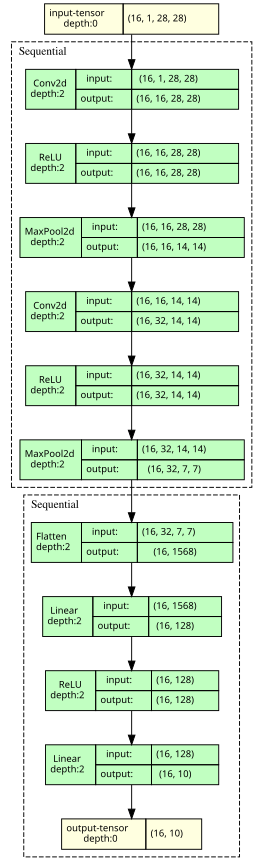

In [ ]:
from torchview import draw_graph

graph = draw_graph(model, input_data = torch.randn(16, 1, 28, 28), expand_nested=True, save_graph=True, filename="simpleCNN",)
graph.visual_graph

# Day 3

In [ ]:
BATCH_SIZE = 64
EPOCHS = 5
LEARNING_RATE = 0.001
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],
                                  std=[0.229,0.224,0.225])
])

train_dataset_2 = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
test_dataset_2 = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

train_loader_2 = DataLoader(train_dataset_2, batch_size=BATCH_SIZE, shuffle=True,num_workers=2)
test_loader_2 = DataLoader(test_dataset_2, batch_size=BATCH_SIZE ,num_workers=2)

NUM_CLASSES = 10

100%|██████████| 170M/170M [00:03<00:00, 44.2MB/s]


In [ ]:
len(train_dataset_2), len(test_dataset_2)

(50000, 10000)

In [ ]:
class simpleCNN(nn.Module):
  def __init__(self):
    super(simpleCNN, self).__init__()
    self.features = nn.Sequential(
        nn.Conv2d(3,32,3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(32,64,3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64*56*56, 256),
        nn.ReLU(),
        nn.Linear(256, NUM_CLASSES),
        )
  def forward(self, x):
    x = self.features(x)
    x = self.classifier(x)
    return x

## Fungsi Training

In [ ]:
def train_model(model,name):
  model = model.to(DEVICE)
  criterion = nn.CrossEntropyLoss()
  optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE)

  print(f"\nTraining {name}")

  for epoch in range(EPOCHS):
    model.train()
    running_loss= 0

    for images, labels in train_loader_2:
      images = images.to(DEVICE)
      labels = labels.to(DEVICE)

      optimizer.zero_grad()
      outputs = model(images)
      loss = criterion(outputs, labels)
      loss.backward()
      optimizer.step()

      running_loss += loss.item()

    print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {running_loss/len(train_loader_2):.3f}")

## Fungsi Testing

In [ ]:
def test_model(model,name):
  model.eval()
  correct = 0
  total = 0

  with torch.no_grad():
    for images, labels in test_loader_2:
      images = images.to(DEVICE)
      labels = labels.to(DEVICE)

      outputs = model(images)

      _, predicted = torch.max(outputs, 1)

      total += labels.size(0)
      correct += (predicted == labels).sum().item()

  accuracy = 100 * correct / total
  print(f"\n{name} Test Accuracy: {accuracy:.2f}%")
  return accuracy

# Proses Training

In [ ]:
simple_model = simpleCNN()
simple_model = train_model(simple_model, "Simple CNN")


Training Simple CNN
Epoch 1/5 | Loss: 1.682


# Proses Testing

In [ ]:
test_model(simple_model, "Simple CNN")